In [1]:
# With the below we prevent oom errors by allowing the GPU memory allocator
# to expand existing memory segments instead of allocating new fixed-size blocks
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
# Installs the HuggingFace datasets library
# !pip install datasets

In [3]:
!pip install -q -U "transformers @ git+https://github.com/huggingface/transformers.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 84.2 MB/s eta 0:00:00


In [4]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Import plotly library
import plotly.graph_objects as go

In [6]:
dataset = load_dataset("ailsntua/QEvasion")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
train_df.head(2)

README.md:   0%|          | 0.00/12.7k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']
Test columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


,title,date,president,url,question_order,interview_question,interview_answer,gpt3.5_summary,gpt3.5_prediction,question,annotator_id,annotator1,annotator2,annotator3,inaudible,multiple_questions,affirmative_questions,index,clarity_label,evasion_label
0,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,How would you respond to the accusation that t...,85,None,None,None,False,False,False,0,Clear Reply,Explicit
1,"The President's News Conference in Hanoi, Vietnam","September 10, 2023",Joseph R. Biden,https://www.presidency.ucsb.edu/documents/the-...,1,Q. Of the Biden administration. And accused th...,"Well, look, first of all, theI am sincere abou...",The question consists of 2 parts: \n1. How wou...,Question part: 1. How would you respond to the...,Do you think President Xi is being sincere abo...,85,None,None,None,False,False,False,1,Ambivalent,General


In [7]:
# with open('test_df.txt', 'w') as file:
#     file.write("Id,Predicted\n")
#     for i, label in enumerate(test_df['clarity_label']):
#         file.write(str(i) + "," + str(label) + "\n")

In [8]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nLabel distribution (Train):")
print(train_df["clarity_label"].value_counts())

print("\nLabel distribution (Test):")
print(test_df["clarity_label"].value_counts())

Train shape: (3448, 20)
Test shape: (308, 20)

Label distribution (Train):
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

Label distribution (Test):
clarity_label
Ambivalent         206
Clear Reply         79
Clear Non-Reply     23
Name: count, dtype: int64


In [9]:
train_df[["question", "interview_answer"]].head(10)

,question,interview_answer
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou..."
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou..."
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p..."
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p..."
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l..."
5,Is there a danger of a cold war?,"Well, I hope I get to see Mr. Xi sooner than l..."
6,When will the President meet Mr. Xi?,"Well, I hope I get to see Mr. Xi sooner than l..."
7,How concerned are you about this lack of cons...,It wasn't so much an agreement that we would t...
8,Concerns about the lack of communication betw...,It's not a wedge issue of the Global South. It...
9,Inquiry about the reaction of Kyiv regarding ...,It's not a wedge issue of the Global South. It...


# **Data Cleaning**

In [10]:
def drop_conflicting_labels(df, name):
    # Find (question, answer) pairs with conflicting clarity labels across different annotators
    label_counts = df.groupby(["question", "interview_answer"])["clarity_label"].nunique()

    conflicting_pairs = label_counts[label_counts > 1].reset_index()
    conflicting_pairs.columns = ["question", "interview_answer", "unique_label_count"]

    print(f"Number of (question, answer) pairs with conflicting labels: {len(conflicting_pairs)}\n")

    # Drop (question, answer) pairs with conflicting clarity labels from the dataframe
    print(f"{name} size before dropping conflicting pairs: {len(df)}")

    df_clean = df.groupby(["question", "interview_answer"]).filter(
        lambda x: x["clarity_label"].nunique() == 1
    ).reset_index(drop=True)

    print(f"{name} size after dropping conflicting pairs: {len(df_clean)}\n")
    return df_clean

In [11]:
train_df = drop_conflicting_labels(train_df, "train_df")

Number of (question, answer) pairs with conflicting labels: 12

train_df size before dropping conflicting pairs: 3448
train_df size after dropping conflicting pairs: 3424



In [12]:
# test_df = drop_conflicting_labels(test_df, name="test_df")

In [13]:
def drop_inaudible(df, name):
    # Drop rows where inaudible = True
    print(f"Number of inaudible rows: {df['inaudible'].sum()}\n")

    print(f"{name} size before dropping inaudible rows: {len(df)}")

    df_clean = df[df["inaudible"] == False].reset_index(drop=True)

    print(f"{name} size after dropping inaudible rows: {len(df_clean)}\n")
    return df_clean

In [14]:
train_df = drop_inaudible(train_df, name="train_df")

Number of inaudible rows: 45

train_df size before dropping inaudible rows: 3424
train_df size after dropping inaudible rows: 3379



In [15]:
# test_df = drop_inaudible(test_df, name="test_df")Copy of without__Quantization technique_A2

In [16]:
# Display rows from the train_df where in interview_answer column has 5 or fewer words

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

train_df["answer_word_count"] = train_df["interview_answer"].apply(lambda x: len(x.split()))

train_df_sorted = train_df[train_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(train_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

pd.reset_option("display.max_rows")
pd.reset_option("display.max_colwidth")

,question,interview_answer,answer_word_count,clarity_label
0,"Discussion of defense budget increase, enemy base strike capability, and Japan-U.S. alliance.",No.,1,Clear Reply
1,Inquiring about the belief in an off-ramp for Vladimir Putin.,Yes.,1,Clear Reply
2,"The question asks if the President is willing to get involved militarily to defend Taiwan, if necessary.",Yes.,1,Clear Reply
3,Analysis of the response to China and the current status of cross-Straits relations,No.,1,Ambivalent
4,Are you satisfied with what came out in the communiqué?,Yes.,1,Clear Reply
5,Reasons for the shortened duration of the summit,Yes.,1,Ambivalent
6,Agreement with President Putin's statement regarding the absence of threats or scare tactics,Yes.,1,Clear Reply
7,Virtual summit participation,Yes.,1,Clear Reply
8,Transparency on the coronavirus origins,Yes.,1,Clear Reply
9,Agreement or disagreement with President Obama's view.,Yes.,1,Clear Reply


In [17]:
test_df["answer_word_count"] = test_df["interview_answer"].apply(lambda x: len(x.split()))

test_df_sorted = test_df[test_df["answer_word_count"] <= 5].sort_values("answer_word_count", ascending=True).reset_index(drop=True)

display(test_df_sorted[["question", "interview_answer", "answer_word_count", "clarity_label"]])

,question,interview_answer,answer_word_count,clarity_label
0,Do you think the decision by your G-20 counter...,Okay.,1,Ambivalent
1,What kind of punishment would you like to see ...,Okay.,1,Ambivalent
2,"Can we go back to North Korea, Mr. President?",Please.,1,Clear Reply
3,Clarification on the stance towards a nuclear ...,No.,1,Clear Reply
4,Previous conversations with Prime Minister Ma...,On Iran?,2,Clear Non-Reply
5,Permission to direct a question to President Hu.,Of course.,2,Clear Reply
6,Confidence in Republicans holding the House an...,"Yes, I am.",3,Clear Reply
7,Would you campaign for Mike Fitzpatrick?,I already have.,3,Clear Reply
8,"Is that a make-or-break issue for you, in term...",I already have.,3,Ambivalent
9,Reappointment of U.S. Attorney Patrick Fitzgerald,As a special prosecutor?,4,Clear Non-Reply


In [18]:
print(f"train_df size before dropping: {len(train_df)}")

# Drop rows with 0 words in the answer
train_df = train_df[train_df["answer_word_count"] > 0].reset_index(drop=True)

print(f"train_df size after dropping: {len(train_df)}")

train_df size before dropping: 3379
train_df size after dropping: 3379


In [19]:
# print(f"test_df size before dropping: {len(test_df)}")

# # Drop rows with 0 words in the answer
# test_df = test_df[test_df["answer_word_count"] > 0].reset_index(drop=True)

# print(f"test_df size after dropping: {len(test_df)}")

# **EDA part**

In [20]:
print(train_df["president"].unique())
print(f"\nTotal unique presidents: {train_df['president'].nunique()}")

['Joseph R. Biden' 'Donald J. Trump' 'Barack Obama' 'George W. Bush']

Total unique presidents: 4


In [21]:
print(train_df["clarity_label"].unique())

['Clear Reply' 'Ambivalent' 'Clear Non-Reply']


In [22]:
# Plot pie chart showing the overall distribution of clarity labels across all presidents
def plot_label_distribution_pie(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    colors = ["#2196F3", "#FF9800", "#F44336"]

    label_counts = df["clarity_label"].value_counts()
    values = [label_counts[label] for label in labels]

    fig = go.Figure(data=[go.Pie(labels=labels, values=values)])

    fig.update_traces(
        hoverinfo='label+percent',
        texttemplate='%{percent}<br>%{value}',
        textfont_size=20,
        marker=dict(colors=colors, line=dict(color='#000000', width=2))
    )

    fig.update_layout(
        title=dict(
          text="Overall Clarity Label Distribution",
          font=dict(size=24, family="Arial Black")
        ),
        legend_title="Clarity Label"
    )

    fig.show()

plot_label_distribution_pie(train_df)

In [23]:
plot_label_distribution_pie(test_df)

In [24]:
# Table and grouped bar chart showing answer length statistics (average, median, min, max) per clarity label
def print_length_statistics(df):
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    rows = []

    for label in labels:
        subset = df[df["clarity_label"] == label]["interview_answer"]
        lengths = subset.apply(lambda x: len(x.split()))

        rows.append({
            "Label": label,
            "Average Length": round(lengths.mean(), 1),
            "Median": round(lengths.median(), 1),
            "Min": lengths.min(),
            "Max": lengths.max()
        })

    result_df = pd.DataFrame(rows).set_index("Label")
    display(result_df)

    print("\n\n")

    metrics = ["Max", "Average Length", "Median", "Min"]
    colors  = ["#F44336", "#FF9800", "#2196F3", "#FFEB3B"]

    fig = go.Figure(data=[
        go.Bar(
            name=metric,
            x=labels,
            y=[row[metric] for row in rows],
            text=[row[metric] for row in rows],
            textposition="outside",
            marker_color=color
        )
        for metric, color in zip(metrics, colors)
    ])

    fig.update_layout(
        barmode="group",
        title=dict(
            text="Answer Length Statistics per Clarity Label",
            font=dict(size=24, family="Arial Black")
        ),
        yaxis_title="Length (words)",
        legend_title="Metric",
    )

    fig.update_xaxes(
        tickangle=0,
        tickfont=dict(size=12, color="black"),
        title_text="Clarity Label",
        title_standoff=40
    )

    fig.show()

print_length_statistics(train_df)

,Average Length,Median,Min,Max
Label,,,,
Clear Reply,267.9,190.0,1,1592
Ambivalent,327.9,241.0,1,2117
Clear Non-Reply,136.0,40.0,1,1407


# **Prompting Strategies Experiments**

In [25]:
import torch
import time
import random

In [26]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [27]:
# GPU SETUP
# If there's a GPU available...
if torch.cuda.is_available():

    # Tell PyTorch to use the GPU.
    device = torch.device("cuda")

    print('There are %d GPU(s) available.' % torch.cuda.device_count())

    print('We will use the GPU:', torch.cuda.get_device_name(0))

# If not...
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 2 GPU(s) available.
We will use the GPU: Tesla T4


In [28]:
VALID_LABELS = {"Clear Reply", "Ambivalent", "Clear Non-Reply"}

In [29]:
from transformers import AutoModelForCausalLM, AutoTokenizer

def load_model(model_name):
    print(f"Loading model: {model_name} ...")

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    # Left padding ensures all sequences end at the same position,
    # which is required for correct alignment during batch inference
    tokenizer.padding_side = "left"

    # Use eos_token as pad_token if the model doesn't define one
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=torch.bfloat16,
        device_map="auto"
    )
    model.eval()

    print(f"Done loading: {model_name}")
    return model, tokenizer

## **zero-shot prompting**

In [30]:
system_zero_shot = """You are an expert political discourse analyst.
Given a political interview question and its corresponding answer, classify the answer into exactly one of the following categories:
- Clear Reply: The politician directly and clearly answers the question asked.
- Ambivalent: The politician gives a vague or partially relevant response.
- Clear Non-Reply: The politician completely avoids or deflects the question.

Respond with the label only. Do not explain."""


# "Label:" acts as an output indicator it nudges the model to complete
# the text with just the label, rather than generating a full explanation
def build_zero_shot(example):
    return f"""Question: {example["question"]}
Answer: {example["interview_answer"]}
Label:"""

In [31]:
# Display 50 examples per class from the training set
# to manually identify the best representative example for each label in few-shot prompting
pd.set_option("display.max_colwidth", None)

for label in ["Clear Reply", "Ambivalent", "Clear Non-Reply"]:
    print(f"\n{'='*60}")
    print(f"CLASS: {label}")
    print(f"{'='*60}")
    subset = train_df[train_df["clarity_label"] == label][["question", "interview_answer"]].head(50)
    display(subset)


CLASS: Clear Reply


question  \
0                                                                                                             How would you respond to the accusation that the United States is containing China while pushing for diplomatic talks?   
4                                                                                                                                                 Is the President's engagement with Asian countries a sign of a cold war mentality?   
8                                                                      Concerns about the lack of communication between the interviewee and President Xi of China, and the potential destabilization of the U.S.-China relationship.   
9     Inquiry about the reaction of Kyiv regarding the G-20 communique not naming Russia as the aggressor, and if this issue is becoming divisive with the Global South, and how it impacts the interviewee's commitment to Ukraine.   
10                                                                                                      Compared to the previous summits, what would be the most significant outcome that President Yoon gained through this summit?   
14                                                                                                                                           ensuring Finland that the U.S. will remain a reliable NATO partner for decades to come.   
15                                                                                                                       Are you worried that the political instability in the U.S. will cause issues in the alliance in the future?   
22                                                                        Does this raise any new concerns about Putin potentially doing more drastic things regarding Ukraine, like nuclear weapons, or potentially against the U.S   
28                                                                                                           Did the comments about President Xi undermine or complicate the progress made in maintaining a relationship with China?   
31                                                                                                                Republican-led States passing anti-LGBTQ laws and the rise of intimidation and violence against LGBTQ individuals.   
32                                                                                                                      Parents of a transgender girl in Texas considering leaving the State and the country due to safety concerns.   
38                                                                  Is the new Washington consensus that you and your National Security Adviser set out simply another way of saying America first, which some overseas think it is?   
40                                                                                                     What do you say to Americans to convince them that they should trust the independence and fairness of the Justice Department?   
42                                                                                                                                                 Concern about accepting a cap or freezing spending and its impact on the economy.   
44                                                                                                                                                          But you don't think the spending cuts themselves will cause a recession?   
47                                                                                                                                                                          you do expect these F-16s to take part in this conflict?   
48                                                                                                                                                         What assurances do you have that providing F-16s won't escalate this war?   
56                                          


CLASS: Ambivalent


question  \
1                                                                               Do you think President Xi is being sincere about getting the relationship back on track as he bans Apple in China?   
2                            Do you believe the country's slowdown and growth could risk destabilizing the global economy or cause China to be more aggressive defensively, including with Taiwan?   
3                                                       Are you worried about the meeting between President Putin and Kim Jong Un, if that could mean Russia has more gains in the war in Ukraine?   
5                                                                                                                                                                 Is there a danger of a cold war?   
6                                                                                                                                                             When will the President meet Mr. Xi?   
7                                                                                                                                              How concerned are you about this lack of consensus?   
11                                                                                     From the perspective of the people of Korea, what would be the benefit felt from the strengthening of ties?   
12  What kind of shift would there be in President Biden's policy regarding human rights issues and a free and peaceful Korean Peninsula, and what specific solutions does he have in this regard?   
13                                                                                                                                            Is Mr. President winning the competition with China?   
16                                                                                                       Concerns about the comments motivating Putin or discouraging him from peace negotiations.   
17                                                                                                                                                      The risk of the war dragging on for years.   
18                                                                                                                                    The possibility of the war ending with Putin still in power.   
19                                                                                                            Envisioning the possibility of the U.S. having a permanent military base in Finland.   
20                                                                                                                        How does the NATOization of Finland change Finland's place in the world?   
21                                                                                                                                                                         NATO membership process   
24                                                                                             Tying abortion rights to defense issues and the block on military promotions by Senator Tuberville.   
25                                                                                                                    Would President Biden be willing to talk with Tuberville to find a solution?   
26                                                                                                 As a leader who shares a border with Russia - What more do you want to see done to deter Putin?   
27                                                                              Working on fortifying the fence along the border between Finland and Russia - Is there anything that concerns you?   
30                                    What is your message to those who believe that your administration is overlooking the targeting of religious minorities and a crackdown on dissent in India?   
33                          


CLASS: Clear Non-Reply


,question,interview_answer
23,Does the firing of the general and the rebellion by Prigozhin indicate any potential future actions by Putin?,"Well, first of all, they already interfered in American elections. So that would not be anything new. They did that last time—they tried to.But with regard to—I don't think there's any real prospect—you never know—but of Putin using nuclear weapons. Not only has the West, but China and the rest of the world has said: That's—don't go there. Don't go there. Number two.Number three, I think that determining what happens to Prigozhin and what happens to Vilnius—I mean—excuse me, what happens when we discussed this in Vilnius is, God only knows what he's likely to do. Well, I'm not even sure—we're not even sure where he is and what relationship he has. If I were he, I'd be careful what I ate. I'd be keeping my eye on my menu.But all kidding aside, I who knows? I don't know. I don't think any of us know for sure what the future of Prigozhin is in Russia. And so I don't know how to answer that question beyond that."
29,What is the message to those who say the administration is overlooking the targeting of religious minorities and crackdown on dissent in Prime Minister Modi's country?,"The answer to your first question is: No. You know, what—when we're talking to our allies and partners around the world, including India, we let the idea of my choosing and avoiding saying what I think is the facts with regard to the relationship with India—with China is—just not something I'm going to change very much.I think we—I believe that—and I've said this for some time—that the hysteria about the relationship with China is collapsing and moving, et cetera, et cetera—we had an incident that caused some confusion, you might say. But President—but Secretary Blinken had a great trip to China. I expect to be meeting with President Xi sometime in the future, in the near term. And I don't think it's had any real consequence.And what was your second question?"
45,President Zelenskyy's communication about the big counteroffensive and whether it is underway or not.,"Well, I'll tell you exactly when they're going to move, exactly where they're going to go. He told me—[]—come on. God love you. I'm going to—even if I knew precisely, you think I'm going to tell you what they're going to do in terms of their offensive?"
85,"Was there any discussion related to the U.S. assessments that Russia would not take escalatory action now that Patriots are being sent, will be delivered—a Patriot battery will be delivered?","Let me answer the first question—the first part of your question. You know, I get kidded for saying that there's—all politics is personal. It's all about looking someone in the eye. And I mean it sincerely.I don't think there's any, any, any substitute for sitting down face to face with a friend or a foe and looking them in the eye. And that's exactly what's happening at this moment. We've done that more than once, and we're going to continue to do it.And the winter is setting in, and Putin is increasingly going after civilian targets and women and children, orphanages. This guy is—well—but he's going to fail. And he's going to fail. He's already failed, because he now knows that there's no way he's ever going to occupy all of Ukraine. There's no way in which he's going to be accepted by the Ukrainian people.And so he's failed in the past. And it was very important for him and everyone else to see that President Zelenskyy and I are united, two countries together, to make sure he cannot succeed.And I think—I may be mistaken, but I know—I judge every leader by the way they—what they say to me, their consistency, and looking me in the eye.This guy——[]——has in his—to his very soul is who he says he is. It's clear who he is. He's willing to give his life for his country and all the folks who are with—came with him today.And so I think it's—he—it's important for him to know we are going to do everything in our power—ev

## **few-shot prompting**

In [32]:
# few-shot examples one per class, pulled directly from the training data by row index
# Row 135 = Clear Reply, Row 6 = Ambivalent, Row 214 = Clear Non-Reply
# Chosen for being the clearest and most unambiguous representative of each label

# Clear Reply — Row 135
# Question: How does the sentiment of these Americans factor into the President's decision about whether or not to run for reelection?
# Answer: It doesn't.
# Why: Perfectly direct, zero ambiguity. Clear answers exactly what was asked. No hedging, no deflection

# Ambivalent — Row 6
# Question: When will the President meet Mr. Xi?
# Answer: Well, I hope I get to see Mr. Xi sooner than later...
# Why: The question asks a simple and specific thing (when?) but the answer never addresses it.
# The answer may partially touch the topic but never directly answers the specific question asked. Classic Ambivalen

# Clear Non-Reply — Row 214
# Question: Can you tell us who those five Republican Senators are?
# Answer: Sure. No. Are you kidding me? I maintain confidentiality.
# Why: Explicit flat refusal. No deflection, no changing subject just a direct refusal to answer

FEW_SHOT_EXAMPLES = [
    {
        "question": train_df.loc[135, "question"],
        "answer": train_df.loc[135, "interview_answer"],
        "label": "Clear Reply",
        "reason": "The answer directly and clearly addresses exactly what was asked with no hedging or deflection."
    },
    {
        "question": train_df.loc[6, "question"],
        "answer": train_df.loc[6, "interview_answer"],
        "label": "Ambivalent",
        "reason": "The answer may partially touch or be completely on topic but never directly answers the specific question asked."
    },
    {
        "question": train_df.loc[214, "question"],
        "answer": train_df.loc[214, "interview_answer"],
        "label": "Clear Non-Reply",
        "reason": "The politician explicitly refuses to answer the question at all."
    },
]

# Verify
for ex in FEW_SHOT_EXAMPLES:
    print(f"Label: {ex['label']}")
    print(f"Question: {ex['question'][:80]}...")
    print()

Label: Clear Reply
Question: How does the sentiment of these Americans factor into the President's decision a...

Label: Ambivalent
Question: When will the President meet Mr. Xi?...

Label: Clear Non-Reply
Question:  Can you tell us who those five Republican Senators are?...



In [33]:
# few-shot uses the same system prompt as zero-shot
# The only difference is in the user prompt, where the 3 labeled examples are added before the actual question

# The 3 labeled examples are shown to the model before the actual question
# This teaches the model the expected pattern: Question -> Answer -> Label -> Reason
# The Reason field explains why each label was chosen, helping the model better understand the classification logic
# "Label:" at the end acts as output indicator
def build_few_shot(example):
    examples_text = ""
    for ex in FEW_SHOT_EXAMPLES:
        examples_text += f"""Question: {ex["question"]}
Answer: {ex["answer"]}
Label: {ex["label"]}
Reason: {ex["reason"]}\n\n"""

    return f"""{examples_text}Question: {example["question"]}
Answer: {example["interview_answer"]}
Label:"""

## **chain-of-thought (CoT) prompting**

In [34]:
# chain-of-thought: instead of jumping straight to the label, the model is asked
# to reason step by step first. This helps especially with Ambivalent cases.
# The final label is extracted from the last line of the response.

system_cot = """You are an expert political discourse analyst.
Given a political interview question and its corresponding answer, classify the answer into exactly one of the following categories:
- Clear Reply: The politician directly and clearly answers the question asked.
- Ambivalent: The politician gives a vague or partially relevant response.
- Clear Non-Reply: The politician completely avoids or deflects the question.

Think step by step:
Step 1: What is the question asking?
Step 2: Does the answer directly address the question?
Step 3: Based on your reasoning, what is the label?

End your response with exactly this format:
Label: <label>"""

# No "Label:" at the end here because the model needs space to reason first
# The label will be at the end of the model's response after its reasoning
def build_cot(example):
    return f"""Question: {example["question"]}
Answer: {example["interview_answer"]}"""

## **Persona Prompting**

In [35]:
# Persona prompt: gives the model a detailed expert persona with explicit methodology.
# More specific than zero-shot i.e. the persona includes background, experience and a clear step-by-step methodology.
# The idea is that framing the model as an expert may lead to more accurate and consistent classifications

system_role = """You are a political scientist with 20 years of experience analyzing political interview responses.
You have published research on how politicians respond to questions.
Your methodology involves three steps:
1. Identify what the question is specifically asking.
2. Analyze whether the answer directly and fully addresses that specific question.
3. Classify based on the degree of directness.

Based on your expertise, classify the answer into exactly one of the following categories:
- Clear Reply: The politician directly and clearly answers the question asked.
- Ambivalent: The politician gives a vague or partially relevant response.
- Clear Non-Reply: The politician completely avoids or deflects the question.

Respond with the label only. Do not explain."""

# Same user prompt structure as zero-shot
# The difference is only in the system prompt which now carries the expert persona
# "Label:" at the end acts as output indicator
def build_role_prompt(example):
    return f"""Question: {example["question"]}
Answer: {example["interview_answer"]}
Label:"""

## **Persona + few-shot Hybrid Prompting**


In [36]:
# Persona + few-shot hybrid prompt
# Combines the expert persona from system_role with the few-shot examples from build_few_shot
# The system prompt sets the expert persona and methodology
# The user prompt (build_few_shot) provides 3 labeled examples to guide the model
# Each example follows the pattern: Question -> Answer -> Label -> Reason
# The Reason field explains why each label was chosen, helping the model better understand the classification logic
# This combination gives the model both:
#   1. Expert context and classification methodology (from persona)
#   2. Concrete labeled examples to follow, each with a Reason explaining why the label was chosen (from few-shot)
# No new build function needed — reuses build_few_shot for the user prompt
# The key difference from regular few-shot: system_zero_shot is replaced with system_persona_few

system_persona_few = """You are a political scientist with 20 years of experience analyzing political interview responses.
You have published research on how politicians respond to questions.
Your methodology involves three steps:
1. Identify what the question is specifically asking.
2. Analyze whether the answer directly and fully addresses that specific question.
3. Classify based on the degree of directness.

Based on your expertise, classify the answer into exactly one of the following categories:
- Clear Reply: The politician directly and clearly answers the question asked.
- Ambivalent: The politician gives a vague or partially relevant response.
- Clear Non-Reply: The politician completely avoids or deflects the question.

Respond with the label only. Do not explain."""

## **Persona + cot Hybrid Prompting**

In [37]:
# Persona + CoT hybrid prompt
# Combines the expert persona from system_role with the cot reasoning steps from system_cot
# The system prompt sets the expert persona AND asks for step-by-step reasoning
# The user prompt (build_cot) provides just the question and answer, no examples needed here
# This combination gives the model both:
#   1. Expert context and classification methodology (from persona)
#   2. Step-by-step reasoning before classifying (from cot)
# No new build function needed — reuses build_cot for the user prompt
# The final label is extracted from the end of the response using normalize_label_cot()

system_persona_cot = """You are a political scientist with 20 years of experience analyzing political interview responses.
You have published research on how politicians respond to questions.

Given a political interview question and its corresponding answer, classify the answer into exactly one of the following categories:
- Clear Reply: The politician directly and clearly answers the question asked.
- Ambivalent: The politician gives a vague or partially relevant response.
- Clear Non-Reply: The politician completely avoids or deflects the question.

Think step by step:
Step 1: Identify what the question is specifically asking.
Step 2: Analyze whether the answer directly and fully addresses that specific question.
Step 3: Classify based on the degree of directness.

End your response with exactly this format:
Label: <label>"""

## **Evaluation Setup & Model Runs**

In [38]:
from sklearn.model_selection import train_test_split

# First create a fixed pool of 1000 samples using a fixed seed (SEED = 42)
# All subsets regardless of size will always be drawn from within this same pool
# This ensures fair comparison across different sample sizes
# Thanks to the fixed seed, the same 1000 samples are guaranteed in every run
_, full_experiment_subset = train_test_split(
    train_df,
    test_size=1000,
    random_state=SEED,
    stratify=train_df["clarity_label"]
)

# Change SAMPLE_SIZE to experiment with different sizes: 100, 200, 300, 500 etc
SAMPLE_SIZE = 400

_, experiment_subset = train_test_split(
    full_experiment_subset,
    test_size=SAMPLE_SIZE,
    random_state=SEED,
    stratify=full_experiment_subset["clarity_label"]
)
experiment_subset = experiment_subset.reset_index(drop=True)

print(f"Experiment subset size: {len(experiment_subset)}")
print(f"\nLabel distribution:")
print(experiment_subset["clarity_label"].value_counts())

Experiment subset size: 400

Label distribution:
clarity_label
Ambivalent         237
Clear Reply        122
Clear Non-Reply     41
Name: count, dtype: int64


In [39]:
# Number of samples processed in each batch
BATCH_SIZE = 8

# generation_kwargs contains the optimal sampling parameters for each model
# taken directly from the official Hugging Face model cards to ensure best results
def run_experiment(model, tokenizer, dataset, build_prompt_fn, system_prompt, enable_thinking=False, max_new_tokens=10, generation_kwargs=None):


    # Default to empty dict if no generation kwargs are provided
    # During some experiments we tested without passing generation_kwargs
    # so this ensures the function still works in that case to ensure reproducibility
    # In the final version generation_kwargs is always provided according to the model card
    if generation_kwargs is None:
        generation_kwargs = {}

    # Build all prompts by applying the chat template (system + user) to each example in the dataset
    prompts = []
    for _, row in dataset.iterrows():
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": build_prompt_fn(row)}
        ]
        prompts.append(
            tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=enable_thinking # Only enabled for Qwen3.5-4B thinking mode
            )
        )

    # Process prompts in batches to avoid oom errors
    results = []
    for i in range(0, len(prompts), BATCH_SIZE):
        batch_prompts = prompts[i:i + BATCH_SIZE]
        batch_rows = dataset.iloc[i:i + BATCH_SIZE]

        inputs = tokenizer(
            batch_prompts,
            return_tensors="pt",
            padding=True
        ).to(model.device)

        # Generate responses for the current batch using the model
        # Gradient computation is disabled since we are only doing inference not training
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                pad_token_id=tokenizer.eos_token_id,
                **generation_kwargs, # Unpack optimal sampling parameters from the model card (do_sample, temperature, top_p, top_k)
            )

        # Decode only the newly generated tokens by slicing off the input tokens
        for j, (_, row) in enumerate(batch_rows.iterrows()):
            response = tokenizer.decode(
                outputs[j][inputs["input_ids"].shape[1]:],  # Skip input tokens, keep only generated tokens
                skip_special_tokens=True  # Remove special tokens like <eos>, <pad> from the response
            )

            # Store the question, model response and gold label for this sample
            results.append({
                "question": row["question"],
                "response": response.strip(),
                "gold": row["clarity_label"]
            })


    # return list of dicts, each containing the question, raw model response and gold label of each sample
    return results

In [40]:
#------------------------------------------Output Normalization & Prediction Extraction Part--------------------------------------#


# The model sometimes returns the label with extra text around it
# This function extracts the valid label from the response
# If no valid label is found returns INVALID marker
def normalize_label(response):
    text = response.strip()

    # Remove <think>...</think> blocks, the 4B model sometimes generates these
    # even with enable_thinking=False
    if "</think>" in text:
        text = text.split("</think>")[-1].strip()

    # Take only the first line ignore garbage after the first newline
    text = text.split("\n")[0].strip()

    # Check if the response is already a valid label
    if text in VALID_LABELS:
        return text

    # Check if any valid label appears inside the response
    for label in VALID_LABELS:
        if label.lower() in text.lower():
            return label

    # No valid label found return INVALID marker
    return "INVALID"


# Special normalization for cot responses
# cot responses contain reasoning text before the label
# so we search from the end of the response to find "Label: X"
# instead of searching from the beginning which could find the labels names in the reasoning text
# I am saying this because when running the experiments for the cot responses I saw for example during reasoning the model wrote
# "it's not a Clear Reply" and normalize_label() would incorrectly return "Clear Reply" because it found first this label name in the text
def normalize_label_cot(response):
    text = response.strip()

    # Remove <think>...</think> blocks, 4B model sometimes generates these
    # even with enable_thinking=False
    if "</think>" in text:
        text = text.split("</think>")[-1].strip()

    # Search from the end of the response for "Label: X" pattern
    lines = text.split('\n')
    for line in reversed(lines):
        line = line.strip()
        if line.startswith("Label:"):
            label = line.replace("Label:", "").strip()
            if label in VALID_LABELS:
                return label
            # Check if any valid label appears in this line
            for valid_label in VALID_LABELS:
                if valid_label.lower() in label.lower():
                    return valid_label

    # Fallback to standard normalize if no "Label:" line found
    return normalize_label(response)


# Apply normalization to a list of results from run_experiment()
# is_cot=True uses normalize_label_cot() which searches from the end
# is_cot=False uses normalize_label() which searches only in the first line of the response
def extract_predictions(results, is_cot=False):

    predictions = []
    gold_labels = []

    # Track how many responses could not be mapped to a valid label
    invalid_count = 0

    for r in results:
        if is_cot:
            pred = normalize_label_cot(r["response"])
        else:
            pred = normalize_label(r["response"])

        if pred == "INVALID":
            invalid_count += 1

        predictions.append(pred)
        gold_labels.append(r["gold"])

    print(f"Invalid predictions: {invalid_count} out of {len(results)} ({invalid_count/len(results)*100:.1f}%)")

    # return the list of predicted labels and the corresponding gold labels
    return predictions, gold_labels

#---------------------------------------------------------------------------------------------------------------------------------#

In [41]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report)

def compute_metrics(predictions, gold_labels, model_name, strategy_name):

    accuracy = accuracy_score(gold_labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        gold_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    macro_f1 = precision_recall_fscore_support(
        gold_labels,
        predictions,
        average="macro",
        zero_division=0
    )[2]

    print(f"\n{'='*60}")
    print(f"Model: {model_name}")
    print(f"Strategy: {strategy_name}")
    print(f"{'='*60}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1: {f1:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(gold_labels, predictions, zero_division=0))

    return {
        "model" : model_name,
        "strategy" : strategy_name,
        "accuracy" : accuracy,
        "precision" : precision,
        "recall" : recall,
        "f1" : f1,
        "macro_f1" : macro_f1
    }

In [42]:
# List where each entry is a dict containing model name, strategy and evaluation metrics (accuracy, precision, recall, f1, macro_f1)
all_metrics = []

# List where each entry is a dict containing model name, strategy, question, gold label and predicted label for each sample
all_predictions = []

## **Qwen3.5-0.8B Model**

In [43]:
# Load 0.8B model
model_name = "Qwen/Qwen3.5-0.8B"
model, tokenizer = load_model(model_name)

Loading model: Qwen/Qwen3.5-0.8B ...


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/1.75G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Done loading: Qwen/Qwen3.5-0.8B


In [44]:
# Recommended sampling params from Qwen3.5-0.8B model card
gen_kwargs_0_8b = {
    "do_sample": True,
    "temperature": 1.0,
    "top_p": 1.0,
    "top_k": 20,
}

start_0_8b = time.time()


print("Running zero-shot on Qwen3.5-0.8B ...")
results_0_8b_zero = run_experiment(
    model, tokenizer, experiment_subset, build_zero_shot, system_zero_shot,
    max_new_tokens=10, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_zero)
metrics_0_8b_zero = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "zero-shot")
for r, pred in zip(results_0_8b_zero, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "zero-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running few-shot on Qwen3.5-0.8B ...")
results_0_8b_few = run_experiment(
    model, tokenizer, experiment_subset, build_few_shot, system_zero_shot,
    max_new_tokens=10, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_few)
metrics_0_8b_few = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "few-shot")
for r, pred in zip(results_0_8b_few, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running cot on Qwen3.5-0.8B ...")
results_0_8b_cot = run_experiment(
    model, tokenizer, experiment_subset, build_cot, system_cot,
    max_new_tokens=400, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_cot, is_cot=True)
metrics_0_8b_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "cot")
for r, pred in zip(results_0_8b_cot, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "cot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona on Qwen3.5-0.8B ...")
results_0_8b_persona = run_experiment(
    model, tokenizer, experiment_subset, build_role_prompt, system_role,
    max_new_tokens=10, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_persona)
metrics_0_8b_persona = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "persona")
for r, pred in zip(results_0_8b_persona, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "persona", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona+Few-shot on Qwen3.5-0.8B ...")
results_0_8b_persona_few = run_experiment(
    model, tokenizer, experiment_subset, build_few_shot, system_persona_few,
    max_new_tokens=10, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_persona_few)
metrics_0_8b_persona_few = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "persona-few-shot")
for r, pred in zip(results_0_8b_persona_few, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "persona-few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona+CoT on Qwen3.5-0.8B ...")
results_0_8b_persona_cot = run_experiment(
    model, tokenizer, experiment_subset, build_cot, system_persona_cot,
    max_new_tokens=400, generation_kwargs=gen_kwargs_0_8b
)
predictions, gold_labels = extract_predictions(results_0_8b_persona_cot, is_cot=True)
metrics_0_8b_persona_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-0.8B", "persona-cot")
for r, pred in zip(results_0_8b_persona_cot, predictions):
    all_predictions.append({"model": "Qwen3.5-0.8B", "strategy": "persona-cot", "question": r["question"], "gold": r["gold"], "predicted": pred})


time_0_8b = (time.time() - start_0_8b) / 60
print(f"Qwen3.5-0.8B total time: {time_0_8b:.2f} minutes")

all_metrics.extend([metrics_0_8b_zero, metrics_0_8b_few, metrics_0_8b_cot, metrics_0_8b_persona, metrics_0_8b_persona_few, metrics_0_8b_persona_cot])


# print("=== RAW COT RESPONSES WITH NORMALIZATION (first 20) ===")
# for r in results_0_8b_cot[:20]:
#     raw = r['response']
#     normalized = normalize_label_cot(raw)
#     print(f"Gold: {r['gold']}")
#     print(f"Raw response: '{raw}'")
#     print(f"Normalized to: '{normalized}'")
#     print("-" * 50)

Running zero-shot on Qwen3.5-0.8B ...
Invalid predictions: 7 out of 400 (1.8%)

Model: Qwen3.5-0.8B
Strategy: zero-shot
Accuracy: 0.3950
Precision: 0.4897
Recall: 0.3950
F1: 0.4247
Macro F1: 0.2331

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.61      0.53      0.57       237
Clear Non-Reply       0.08      0.24      0.12        41
    Clear Reply       0.39      0.18      0.25       122
        INVALID       0.00      0.00      0.00         0

       accuracy                           0.40       400
      macro avg       0.27      0.24      0.23       400
   weighted avg       0.49      0.40      0.42       400

Running few-shot on Qwen3.5-0.8B ...
Invalid predictions: 13 out of 400 (3.2%)

Model: Qwen3.5-0.8B
Strategy: few-shot
Accuracy: 0.4125
Precision: 0.4450
Recall: 0.4125
F1: 0.4247
Macro F1: 0.2494

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.57      0.54    

## **Qwen3.5-2B Model**

In [45]:
# Free GPU memory before loading next model
import gc
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()
print("GPU memory freed.")

# Load 2B model
model_name = "Qwen/Qwen3.5-2B"
model, tokenizer = load_model(model_name)

GPU memory freed.
Loading model: Qwen/Qwen3.5-2B ...


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/4.55G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Done loading: Qwen/Qwen3.5-2B


In [46]:
# Recommended sampling params from Qwen3.5-2B model card
gen_kwargs_2b = {
    "do_sample": True,
    "temperature": 1.0,
    "top_p": 1.0,
    "top_k": 20,
}

start_2b = time.time()


print("Running zero-shot on Qwen3.5-2B ...")
results_2b_zero = run_experiment(
    model, tokenizer, experiment_subset, build_zero_shot, system_zero_shot,
    max_new_tokens=10, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_zero)
metrics_2b_zero = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "zero-shot")
for r, pred in zip(results_2b_zero, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "zero-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running few-shot on Qwen3.5-2B ...")
results_2b_few = run_experiment(
    model, tokenizer, experiment_subset, build_few_shot, system_zero_shot,
    max_new_tokens=10, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_few)
metrics_2b_few = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "few-shot")
for r, pred in zip(results_2b_few, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running CoT on Qwen3.5-2B ...")
results_2b_cot = run_experiment(
    model, tokenizer, experiment_subset, build_cot, system_cot,
    max_new_tokens=400, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_cot, is_cot=True)
metrics_2b_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "cot")
for r, pred in zip(results_2b_cot, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "cot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona on Qwen3.5-2B ...")
results_2b_persona = run_experiment(
    model, tokenizer, experiment_subset, build_role_prompt, system_role,
    max_new_tokens=10, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_persona)
metrics_2b_persona = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "persona")
for r, pred in zip(results_2b_persona, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "persona", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona+Few-shot on Qwen3.5-2B ...")
results_2b_persona_few = run_experiment(
    model, tokenizer, experiment_subset, build_few_shot, system_persona_few,
    max_new_tokens=10, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_persona_few)
metrics_2b_persona_few = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "persona-few-shot")
for r, pred in zip(results_2b_persona_few, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "persona-few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})


print("Running Persona+CoT on Qwen3.5-2B ...")
results_2b_persona_cot = run_experiment(
    model, tokenizer, experiment_subset, build_cot, system_persona_cot,
    max_new_tokens=400, generation_kwargs=gen_kwargs_2b
)
predictions, gold_labels = extract_predictions(results_2b_persona_cot, is_cot=True)
metrics_2b_persona_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-2B", "persona-cot")
for r, pred in zip(results_2b_persona_cot, predictions):
    all_predictions.append({"model": "Qwen3.5-2B", "strategy": "persona-cot", "question": r["question"], "gold": r["gold"], "predicted": pred})


time_2b = (time.time() - start_2b) / 60
print(f"Qwen3.5-2B total time: {time_2b:.2f} minutes")

all_metrics.extend([metrics_2b_zero, metrics_2b_few, metrics_2b_cot, metrics_2b_persona, metrics_2b_persona_few, metrics_2b_persona_cot])

# print("=== RAW COT RESPONSES WITH NORMALIZATION (first 20) ===")
# for r in results_2b_cot[:20]:
#     raw = r['response']
#     normalized = normalize_label_cot(raw)
#     print(f"Gold: {r['gold']}")
#     print(f"Raw response: '{raw}'")
#     print(f"Normalized to: '{normalized}'")
#     print("-" * 50)

Running zero-shot on Qwen3.5-2B ...
Invalid predictions: 8 out of 400 (2.0%)

Model: Qwen3.5-2B
Strategy: zero-shot
Accuracy: 0.3500
Precision: 0.4344
Recall: 0.3500
F1: 0.3330
Macro F1: 0.2489

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.52      0.19      0.28       237
Clear Non-Reply       0.19      0.39      0.26        41
    Clear Reply       0.36      0.64      0.46       122
        INVALID       0.00      0.00      0.00         0

       accuracy                           0.35       400
      macro avg       0.27      0.31      0.25       400
   weighted avg       0.43      0.35      0.33       400

Running few-shot on Qwen3.5-2B ...
Invalid predictions: 10 out of 400 (2.5%)

Model: Qwen3.5-2B
Strategy: few-shot
Accuracy: 0.3825
Precision: 0.5180
Recall: 0.3825
F1: 0.3729
Macro F1: 0.2650

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.65      0.23      0.34  

## **Qwen3.5-4B Model**

In [47]:
# import gc

# torch.cuda.empty_cache()
# gc.collect()
# torch.cuda.empty_cache()

# print(f"GPU memory free: {torch.cuda.memory_reserved(0)/1024**3:.2f} GB")
# print(f"GPU memory used: {torch.cuda.memory_allocated(0)/1024**3:.2f} GB")

In [48]:
# Free GPU memory before loading next model
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()
print("GPU memory freed.")

# Load 4B model
model_name = "Qwen/Qwen3.5-4B"
model, tokenizer = load_model(model_name)

GPU memory freed.
Loading model: Qwen/Qwen3.5-4B ...


config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Done loading: Qwen/Qwen3.5-4B


In [49]:
# Recommended params from Qwen3.5-4B model card — non-thinking general tasks (used for zero-shot, few-shot, persona and persona+few-shot strategies)
gen_kwargs_4b = {
    "do_sample": True,
    "temperature": 0.7,
    "top_p": 0.8,
    "top_k": 20,
}

# Recommended params from Qwen3.5-4B model card — non-thinking reasoning tasks (used for cot and Persona + cot strategies)
gen_kwargs_4b_cot = {
    "do_sample": True,
    "temperature": 1.0,
    "top_p": 1.0,
    "top_k": 40,
}


BATCH_SIZE = 4

start_4b = time.time()


print("Running zero-shot on Qwen3.5-4B ...")
results_4b_zero = run_experiment(
    model, tokenizer, experiment_subset, build_zero_shot, system_zero_shot,
    enable_thinking=False, max_new_tokens=10, generation_kwargs=gen_kwargs_4b
)
predictions, gold_labels = extract_predictions(results_4b_zero)
metrics_4b_zero = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "zero-shot")
for r, pred in zip(results_4b_zero, predictions):
    all_predictions.append({"model": "Qwen3.5-4B", "strategy": "zero-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


print("Running few-shot on Qwen3.5-4B ...")
results_4b_few = run_experiment(
    model, tokenizer, experiment_subset, build_few_shot, system_zero_shot,
    enable_thinking=False, max_new_tokens=10, generation_kwargs=gen_kwargs_4b
)
predictions, gold_labels = extract_predictions(results_4b_few)
metrics_4b_few = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "few-shot")
for r, pred in zip(results_4b_few, predictions):
    all_predictions.append({"model": "Qwen3.5-4B", "strategy": "few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


print("Running CoT on Qwen3.5-4B ...")
results_4b_cot = run_experiment(
    model, tokenizer, experiment_subset, build_cot, system_cot,
    enable_thinking=False, max_new_tokens=400, generation_kwargs=gen_kwargs_4b_cot
)
predictions, gold_labels = extract_predictions(results_4b_cot, is_cot=True)
metrics_4b_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "cot")
for r, pred in zip(results_4b_cot, predictions):
    all_predictions.append({"model": "Qwen3.5-4B", "strategy": "cot", "question": r["question"], "gold": r["gold"], "predicted": pred})
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


print("Running Persona on Qwen3.5-4B ...")
results_4b_persona = run_experiment(
    model, tokenizer, experiment_subset, build_role_prompt, system_role,
    enable_thinking=False, max_new_tokens=10, generation_kwargs=gen_kwargs_4b
)
predictions, gold_labels = extract_predictions(results_4b_persona)
metrics_4b_persona = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "persona")
for r, pred in zip(results_4b_persona, predictions):
    all_predictions.append({"model": "Qwen3.5-4B", "strategy": "persona", "question": r["question"], "gold": r["gold"], "predicted": pred})
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# print("Running Persona+Few-shot on Qwen3.5-4B ...")
# # Reduce batch size to 2 to avoid oom error because persona+few-shot has a longer input
# # (persona system prompt + 3 few-shot examples each with Question + Answer + Label + Reason)
# # which exceeds GPU memory with BATCH_SIZE = 4
# BATCH_SIZE = 2
# results_4b_persona_few = run_experiment(
#     model, tokenizer, experiment_subset, build_few_shot, system_persona_few,
#     enable_thinking=False, max_new_tokens=10, generation_kwargs=gen_kwargs_4b
# )
# predictions, gold_labels = extract_predictions(results_4b_persona_few)
# metrics_4b_persona_few = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "persona-few-shot")
# for r, pred in zip(results_4b_persona_few, predictions):
#     all_predictions.append({"model": "Qwen3.5-4B", "strategy": "persona-few-shot", "question": r["question"], "gold": r["gold"], "predicted": pred})
# gc.collect()
# torch.cuda.empty_cache()
# torch.cuda.synchronize()


# print("Running Persona+CoT on Qwen3.5-4B ...")
# BATCH_SIZE = 4
# results_4b_persona_cot = run_experiment(
#     model, tokenizer, experiment_subset, build_cot, system_persona_cot,
#     enable_thinking=False, max_new_tokens=400, generation_kwargs=gen_kwargs_4b_cot
# )
# predictions, gold_labels = extract_predictions(results_4b_persona_cot, is_cot=True)
# metrics_4b_persona_cot = compute_metrics(predictions, gold_labels, "Qwen3.5-4B", "persona-cot")
# for r, pred in zip(results_4b_persona_cot, predictions):
#     all_predictions.append({"model": "Qwen3.5-4B", "strategy": "persona-cot", "question": r["question"], "gold": r["gold"], "predicted": pred})
# gc.collect()
# torch.cuda.empty_cache()
# torch.cuda.synchronize()


time_4b = (time.time() - start_4b) / 60
print(f"Qwen3.5-4B total time: {time_4b:.2f} minutes")

# all_metrics.extend([metrics_4b_zero, metrics_4b_few, metrics_4b_cot, metrics_4b_persona, metrics_4b_persona_few, metrics_4b_persona_cot])
all_metrics.extend([metrics_4b_zero, metrics_4b_few, metrics_4b_cot, metrics_4b_persona])


# print("=== RAW COT RESPONSES WITH NORMALIZATION (first 20) ===")
# for r in results_4b_cot[:20]:
#     raw = r['response']
#     normalized = normalize_label_cot(raw)
#     print(f"Gold: {r['gold']}")
#     print(f"Raw response: '{raw}'")
#     print(f"Normalized to: '{normalized}'")
#     print("-" * 50)

Running zero-shot on Qwen3.5-4B ...
Invalid predictions: 0 out of 400 (0.0%)

Model: Qwen3.5-4B
Strategy: zero-shot
Accuracy: 0.3750
Precision: 0.5116
Recall: 0.3750
F1: 0.3429
Macro F1: 0.3502

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.61      0.16      0.25       237
Clear Non-Reply       0.17      0.51      0.25        41
    Clear Reply       0.43      0.75      0.55       122

       accuracy                           0.38       400
      macro avg       0.40      0.47      0.35       400
   weighted avg       0.51      0.38      0.34       400

Running few-shot on Qwen3.5-4B ...
Invalid predictions: 0 out of 400 (0.0%)

Model: Qwen3.5-4B
Strategy: few-shot
Accuracy: 0.3725
Precision: 0.5335
Recall: 0.3725
F1: 0.3208
Macro F1: 0.3520

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.64      0.12      0.21       237
Clear Non-Reply       0.19      0.66      0.30   

In [50]:
metrics_df = pd.DataFrame(all_metrics)
predictions_df = pd.DataFrame(all_predictions)

print(metrics_df)
print(f"\nTotal predictions: {len(predictions_df)}")

           model          strategy  accuracy  precision  recall        f1  \
0   Qwen3.5-0.8B         zero-shot    0.3950   0.489714  0.3950  0.424696   
1   Qwen3.5-0.8B          few-shot    0.4125   0.444994  0.4125  0.424660   
2   Qwen3.5-0.8B               cot    0.2400   0.497244  0.2400  0.273480   
3   Qwen3.5-0.8B           persona    0.2475   0.399360  0.2475  0.280575   
4   Qwen3.5-0.8B  persona-few-shot    0.3675   0.431176  0.3675  0.393354   
5   Qwen3.5-0.8B       persona-cot    0.2925   0.471952  0.2925  0.311999   
6     Qwen3.5-2B         zero-shot    0.3500   0.434390  0.3500  0.332979   
7     Qwen3.5-2B          few-shot    0.3825   0.517989  0.3825  0.372935   
8     Qwen3.5-2B               cot    0.2675   0.509802  0.2675  0.293405   
9     Qwen3.5-2B           persona    0.3275   0.420357  0.3275  0.332863   
10    Qwen3.5-2B  persona-few-shot    0.3400   0.439678  0.3400  0.341917   
11    Qwen3.5-2B       persona-cot    0.3550   0.476902  0.3550  0.397539   

# **Results Visualization**

The following plots provide a visual summary of the experimental results across all 3 models and 4 prompting strategies.

In [51]:
# Plot 1: F1 Group Bar Chart: Compare F1 scores for all 12 combinations

strategies = ["zero-shot", "few-shot", "cot", "persona", "persona-few-shot", "persona-cot"]
models = ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]
colors = ["#2196F3", "#FF9800", "#F44336", "#4CAF50", "#9C27B0", "#FF5722"]

fig = go.Figure()

for strategy, color in zip(strategies, colors):
    strategy_df = metrics_df[metrics_df["strategy"] == strategy]
    f1_values = []
    for m in models:
        row = strategy_df[strategy_df["model"] == m]["f1"]
        f1_values.append(row.values[0] if len(row) > 0 else None)
    texts = [f"{v:.4f}" if v is not None else "" for v in f1_values]

    fig.add_trace(go.Bar(
        name=strategy,
        x=models,
        y=f1_values,
        text=texts,
        textposition="outside",
        textfont=dict(size=10),
        marker=dict(color=color, line=dict(width=0.5, color="white"), opacity=0.9),
        hovertemplate=f"Strategy: {strategy}<br>Model: %{{x}}<br>F1: %{{y:.4f}}<extra></extra>",
    ))

fig.update_layout(
    barmode="group",
    title=dict(text="F1 Score by Model and Prompting Strategy", font=dict(size=24, family="Arial Black")),
    xaxis_title="Model",
    yaxis_title="F1 Score",
    yaxis=dict(range=[0, 1]),
    legend_title="Strategy",
    legend=dict(
        orientation="v",
        yanchor="middle",
        y=0.5,
        xanchor="left",
        x=1.02,
        font=dict(size=11)
    ),
    margin=dict(r=120),
    xaxis=dict(tickmode="array", tickvals=models, tickangle=0, type="category"),
    template="plotly_white",
    height=600,
    width=1000,
)

fig.show()

In [52]:
# Plot 2: Weighted F1 vs Model Size Line Chart

strategies = ["zero-shot", "few-shot", "cot", "persona", "persona-few-shot", "persona-cot"]
models = ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]
colors = ["#2196F3", "#FF9800", "#F44336", "#4CAF50", "#9C27B0", "#FF5722"]
text_positions_per_strategy = [
    ["top center", "top center", "top center"],
    ["bottom center", "bottom right", "top center"],
    ["bottom left", "bottom center", "bottom center"],
    ["top left", "top right", "bottom right"],
    ["top right", "bottom left", "top left"],
    ["bottom right", "top left", "bottom center"],
]


fig = go.Figure()

for strategy, color, textpos in zip(strategies, colors, text_positions_per_strategy):
    strategy_df = metrics_df[metrics_df["strategy"] == strategy]
    f1_values = []
    for m in models:
        row = strategy_df[strategy_df["model"] == m]["f1"]
        f1_values.append(row.values[0] if len(row) > 0 else None)

    fig.add_trace(go.Scatter(
        name=strategy,
        x=models,
        y=f1_values,
        mode="lines+markers",
        marker=dict(size=10, color=color),
        line=dict(color=color, width=2),
        hovertemplate=f"Strategy: {strategy}<br>Model: %{{x}}<br>Weighted F1: %{{y:.4f}}<extra></extra>",
    ))

fig.update_layout(
    title=dict(text="Weighted F1 vs Model Size per Prompting Strategy", font=dict(size=24, family="Arial Black")),
    xaxis_title="Model Size",
    yaxis_title="Weighted F1",
    yaxis=dict(range=[0, 0.7]),
    legend_title="Strategy",
    legend=dict(
        orientation="v",
        yanchor="middle",
        y=0.5,
        xanchor="left",
        x=1.02,
        font=dict(size=11)
    ),
    margin=dict(r=120),
    template="plotly_white",
    height=600,
    width=1200,
)

fig.show()

In [53]:
# Plot 3: Per-Class F1 Heatmap

from sklearn.metrics import f1_score

labels = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]
strategies = ["zero-shot", "few-shot", "cot", "persona", "persona-few-shot", "persona-cot"]
models = ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]

valid_predictions_df = predictions_df[predictions_df["predicted"] != "INVALID"]

# Build matrix
row_labels = []
f1_matrix = []

for model in models:
    for strategy in strategies:
        subset = valid_predictions_df[
            (valid_predictions_df["model"] == model) &
            (valid_predictions_df["strategy"] == strategy)
        ]
        if len(subset) == 0:
          continue
        f1_scores = f1_score(subset["gold"], subset["predicted"], labels=labels, average=None, zero_division=0)
        row_labels.append(f"{model} + {strategy}  ")
        f1_matrix.append([round(v, 4) for v in f1_scores])

fig = go.Figure(data=go.Heatmap(
    z=f1_matrix,
    x=labels,
    y=row_labels,
    colorscale="viridis",
    text=[[f"{v:.3f}" for v in row] for row in f1_matrix],
    texttemplate="%{text}",
    textfont=dict(size=18),
    hoverongaps=False,
    hovertemplate="Combination: %{y}<br>Class: %{x}<br>F1: %{z:.4f}<extra></extra>",
    colorbar=dict(title="F1 Score")
))

fig.update_layout(
    title=dict(text="Per-Class F1 Heatmap by Model and Strategy", font=dict(size=24, family="Arial Black")),
    xaxis_title="Class",
    yaxis_title="Model + Strategy",
    xaxis=dict(tickfont=dict(size=14)),
    yaxis=dict(type="category", tickfont=dict(size=14)),
    template="plotly_white",
    height=600,
    width=900,
)

fig.show()

In [54]:
# Plot 4: Confusion Matrices — Best strategy per model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

label_names = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]
valid_predictions_df = predictions_df[predictions_df["predicted"] != "INVALID"]

best_strategies = {}
for model in ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]:
    model_df = metrics_df[metrics_df["model"] == model]
    best_strategies[model] = model_df.loc[model_df["f1"].idxmax(), "strategy"]

def plot_confusion_matrix(model):
    strategy = best_strategies[model]
    subset = valid_predictions_df[
        (valid_predictions_df["model"] == model) &
        (valid_predictions_df["strategy"] == strategy)
    ]
    cm = confusion_matrix(subset["gold"], subset["predicted"], labels=label_names)
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
    disp.plot(ax=ax, cmap="viridis", colorbar=True)
    ax.grid(False)
    ax.set_title(f"Confusion Matrix — {model} (best: {strategy})", fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    print(f"\nConfusion Matrix (raw counts) — {model} | {strategy}:")
    print(f"Labels: {label_names}")
    print(cm)

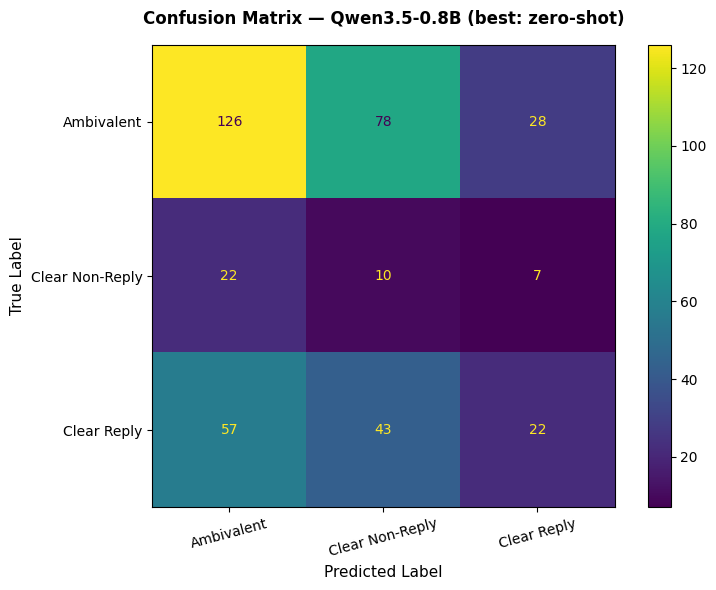


Confusion Matrix (raw counts) — Qwen3.5-0.8B | zero-shot:
Labels: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
[[126  78  28]
 [ 22  10   7]
 [ 57  43  22]]


In [55]:
plot_confusion_matrix("Qwen3.5-0.8B")

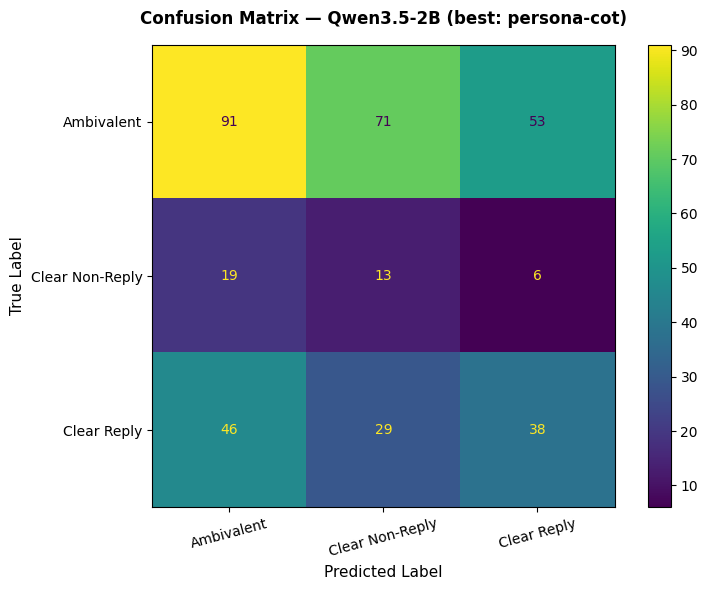


Confusion Matrix (raw counts) — Qwen3.5-2B | persona-cot:
Labels: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
[[91 71 53]
 [19 13  6]
 [46 29 38]]


In [56]:
plot_confusion_matrix("Qwen3.5-2B")

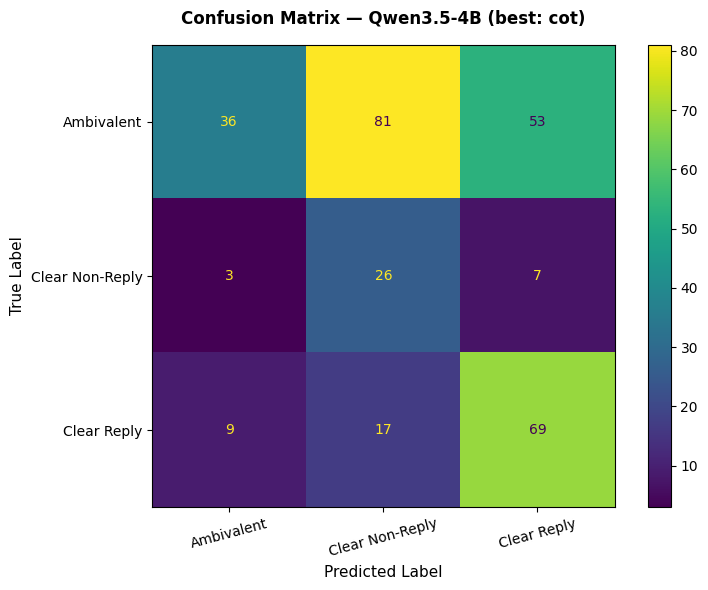


Confusion Matrix (raw counts) — Qwen3.5-4B | cot:
Labels: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
[[36 81 53]
 [ 3 26  7]
 [ 9 17 69]]


In [57]:
plot_confusion_matrix("Qwen3.5-4B")

In [58]:
# Plot 5: Error Distribution — Wrong predictions per class for each model + strategy

labels = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]
strategies = ["zero-shot", "few-shot", "cot", "persona", "persona-few-shot", "persona-cot"]
models = ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]
colors = ["#FF9800", "#F44336", "#2196F3"]

valid_predictions_df = predictions_df[predictions_df["predicted"] != "INVALID"]

x_labels = [f"{m} + {s}" for m in models for s in strategies]

fig = go.Figure()

for label, color in zip(labels, colors):
    error_counts = []
    for model in models:
        for strategy in strategies:
            subset = valid_predictions_df[
                (valid_predictions_df["model"] == model) &
                (valid_predictions_df["strategy"] == strategy)
            ]
            if len(subset) == 0:
              error_counts.append(0)
              continue
            errors = ((subset["gold"] == label) & (subset["predicted"] != label)).sum()
            error_counts.append(errors)

    fig.add_trace(go.Bar(
        name=label,
        x=x_labels,
        y=error_counts,
        text=error_counts,
        textposition="outside",
        textfont=dict(size=10),
        marker=dict(color=color, line=dict(width=0.5, color="white"), opacity=0.9),
        hovertemplate=f"Class: {label}<br>Combination: %{{x}}<br>Errors: %{{y}}<extra></extra>",
    ))

fig.update_layout(
    barmode="group",
    title=dict(text="Error Distribution per Class by Model and Strategy", font=dict(size=24, family="Arial Black")),
    xaxis_title="Model | Strategy",
    yaxis_title="Number of Wrong Predictions",
    legend_title="Class",
    legend=dict(
        orientation="v",
        yanchor="middle",
        y=0.5,
        xanchor="left",
        x=1.02,
        font=dict(size=11)
    ),
    margin=dict(r=120),
    xaxis=dict(tickangle=-45, type="category"),
    template="plotly_white",
    height=600,
    width=1400,
)

fig.show()

In [59]:
# Plot 6: Model Timing — Time taken per model

models = ["Qwen3.5-0.8B", "Qwen3.5-2B", "Qwen3.5-4B"]
times = [time_0_8b, time_2b, time_4b]
colors = ["#2196F3", "#FF9800", "#F44336"]

fig = go.Figure(data=[
    go.Bar(
        x=models,
        y=times,
        text=[f"{t:.2f} min" for t in times],
        textposition="outside",
        textfont=dict(size=12),
        marker=dict(color=colors, line=dict(width=0.5, color="white"), opacity=0.9),
        hovertemplate="Model: %{x}<br>Time: %{y:.2f} minutes<extra></extra>",
    )
])

fig.update_layout(
    title=dict(text="Inference Time per Model (all 4 strategies)", font=dict(size=24, family="Arial Black")),
    xaxis_title="Model",
    yaxis_title="Time (minutes)",
    yaxis=dict(range=[0, max(times) * 1.2]),
    template="plotly_white",
    height=500,
    width=700,
)

fig.show()

## **Test Set Part — Best Model with Best Strategy**

In [60]:
# Free GPU memory
del model
del tokenizer
gc.collect()
torch.cuda.empty_cache()
print("GPU memory freed.")

GPU memory freed.


In [61]:
print(f"Test set size: {len(test_df)}")
print(f"\nLabel distribution:")
print(test_df["clarity_label"].value_counts())

Test set size: 308

Label distribution:
clarity_label
Ambivalent         206
Clear Reply         79
Clear Non-Reply     23
Name: count, dtype: int64


In [62]:
best_row = metrics_df.loc[metrics_df["f1"].idxmax()]
best_model_name = best_row["model"]
best_strategy_name = best_row["strategy"]

# Map each strategy to its (prompt builder function, system prompt, max_new_tokens)
strategy_map = {
    "zero-shot": (build_zero_shot, system_zero_shot, 10),
    "few-shot": (build_few_shot, system_zero_shot, 10),
    "cot": (build_cot, system_cot, 400),
    "persona": (build_role_prompt, system_role, 10),
    "persona-few-shot": (build_few_shot, system_persona_few, 10),
    "persona-cot": (build_cot, system_persona_cot, 400),
}

# Map each model to its recommended generation kwargs from the model card
gen_kwargs_map = {
    "Qwen3.5-0.8B": gen_kwargs_0_8b,
    "Qwen3.5-2B": gen_kwargs_2b,
    "Qwen3.5-4B": gen_kwargs_4b,
}

# Special case: The model 4B with cot and Persona+cot strategy use different kwargs (gen_kwargs_4b_cot)
# because the model card recommends different parameters for reasoning tasks
# So we check if the best model is 4B and the best strategy is cot or Persona+cot
if best_model_name == "Qwen3.5-4B" and best_strategy_name in ["cot", "persona-cot"]:
    best_gen_kwargs = gen_kwargs_4b_cot
else:
    best_gen_kwargs = gen_kwargs_map[best_model_name]


build_fn, system_prompt, max_tokens = strategy_map[best_strategy_name]
is_cot = best_strategy_name in ["cot", "persona-cot"]
enable_thinking = best_model_name == "Qwen3.5-4B"

print(f"Best model: {best_model_name}")
print(f"Best strategy: {best_strategy_name}")
print(f"F1: {best_row['f1']:.4f}")
print(f"Macro F1: {best_row['macro_f1']:.4f}")

Best model: Qwen3.5-0.8B
Best strategy: zero-shot
F1: 0.4247
Macro F1: 0.2331


In [63]:
# Load the best model
model, tokenizer = load_model(f"Qwen/{best_model_name}")

Loading model: Qwen/Qwen3.5-0.8B ...


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Done loading: Qwen/Qwen3.5-0.8B


In [64]:
start_test = time.time()

# Run the best strategy on the full test set
results_test = run_experiment(
    model, tokenizer, test_df,
    build_fn, system_prompt,
    enable_thinking=enable_thinking,
    max_new_tokens=max_tokens,
    generation_kwargs=best_gen_kwargs
)

test_predictions, test_gold = extract_predictions(results_test, is_cot=is_cot)

time_test = (time.time() - start_test) / 60
print(f"Test set inference time: {time_test:.2f} minutes")

Invalid predictions: 4 out of 308 (1.3%)
Test set inference time: 3.13 minutes


In [65]:
_ = compute_metrics(test_predictions, test_gold, best_model_name, best_strategy_name)


Model: Qwen3.5-0.8B
Strategy: zero-shot
Accuracy: 0.4091
Precision: 0.5482
Recall: 0.4091
F1: 0.4628
Macro F1: 0.2241

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent       0.69      0.52      0.59       206
Clear Non-Reply       0.04      0.17      0.06        23
    Clear Reply       0.33      0.19      0.24        79
        INVALID       0.00      0.00      0.00         0

       accuracy                           0.41       308
      macro avg       0.26      0.22      0.22       308
   weighted avg       0.55      0.41      0.46       308



In [66]:
with open("submission.csv", "w") as file:
    file.write("Id,Predicted\n")
    for i, prediction in enumerate(test_predictions):
        file.write(f"{i},{prediction}\n")